<center><h1>Tong_Stephanie_HW7</h1></center>

Name: Stephanie Tong
<br>
Github Username: tongstep
<br>
USC ID: 2614015757

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

Import packages

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split,GridSearchCV
from sklearn.metrics import accuracy_score, hamming_loss, calinski_harabasz_score
from sklearn.svm import SVC, LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

import warnings
from sklearn.exceptions import ConvergenceWarning

warnings.simplefilter("ignore", ConvergenceWarning)

### (a) Download the Anuran Calls (MFCCs) Data Set

In [2]:
df = pd.read_csv("../data/Frogs_MFCCs.csv")

print(df.head())
print(df.columns.tolist())

   MFCCs_ 1  MFCCs_ 2  MFCCs_ 3  MFCCs_ 4  MFCCs_ 5  MFCCs_ 6  MFCCs_ 7  \
0       1.0  0.152936 -0.105586  0.200722  0.317201  0.260764  0.100945   
1       1.0  0.171534 -0.098975  0.268425  0.338672  0.268353  0.060835   
2       1.0  0.152317 -0.082973  0.287128  0.276014  0.189867  0.008714   
3       1.0  0.224392  0.118985  0.329432  0.372088  0.361005  0.015501   
4       1.0  0.087817 -0.068345  0.306967  0.330923  0.249144  0.006884   

   MFCCs_ 8  MFCCs_ 9  MFCCs_10  ...  MFCCs_17  MFCCs_18  MFCCs_19  MFCCs_20  \
0 -0.150063 -0.171128  0.124676  ... -0.108351 -0.077623 -0.009568  0.057684   
1 -0.222475 -0.207693  0.170883  ... -0.090974 -0.056510 -0.035303  0.020140   
2 -0.242234 -0.219153  0.232538  ... -0.050691 -0.023590 -0.066722 -0.025083   
3 -0.194347 -0.098181  0.270375  ... -0.136009 -0.177037 -0.130498 -0.054766   
4 -0.265423 -0.172700  0.266434  ... -0.048885 -0.053074 -0.088550 -0.031346   

   MFCCs_21  MFCCs_22           Family      Genus         Species  R

In [3]:
X = df.drop(columns=["Family", "Genus", "Species", "RecordID"])
y = df[["Family", "Genus", "Species"]]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)
print("Number of classes:")
print(y.nunique())

Training: (5036, 22)
Testing: (2159, 22)
Number of classes:
Family      4
Genus       8
Species    10
dtype: int64


### (b) Train a classifier for each label

#### (i) Research

Exact match:
- shows the percentage of samples where all the predicted labels for an observations matches the entire set of true labels (so whether they are all correct). In this problem, Family, Genus, and Species need to all match the actual labels for the prediction to count as correct.

Hamming Loss:
- shows the proportion of labels that are predicted incorrectly. A lower hamming loss means better predictions.

Hamming Score:
- shows the proportion of labels that are predited correctly. A higher hamming score means better predictions, and it's calculated by doing 1-Hamming Loss

#### (ii) Train a SVM for each of the labels

In [4]:
C_params = [0.001, 1, 1000, 1000000]
sig_params = [0.1, 0.5, 1, 1.5, 2]


for column in ["Family", "Genus", "Species"]:
    classes = y_train[column].unique()

    for C in C_params:
        for sigma in sig_params:
            scores = []

            for label in classes:
                y_binary = (y_train[column] == label).astype(int)

                svm = SVC(kernel="rbf", C=C, gamma=1/(2*sigma**2))
                svm.fit(X_train, y_binary)

                scores.append(svm.decision_function(X_train))

            y_pred = classes[np.argmax(scores, axis=0)]
            accuracy = accuracy_score(y_train[column], y_pred)

            print(column, "C:", C, "Sigma:", sigma, "Training Accuracy:", accuracy)

Family C: 0.001 Sigma: 0.1 Training Accuracy: 0.6102065131056394
Family C: 0.001 Sigma: 0.5 Training Accuracy: 0.6102065131056394
Family C: 0.001 Sigma: 1 Training Accuracy: 0.6102065131056394
Family C: 0.001 Sigma: 1.5 Training Accuracy: 0.6102065131056394
Family C: 0.001 Sigma: 2 Training Accuracy: 0.6102065131056394
Family C: 1 Sigma: 0.1 Training Accuracy: 1.0
Family C: 1 Sigma: 0.5 Training Accuracy: 0.9948371723590151
Family C: 1 Sigma: 1 Training Accuracy: 0.9747815726767276
Family C: 1 Sigma: 1.5 Training Accuracy: 0.9616759332803813
Family C: 1 Sigma: 2 Training Accuracy: 0.9473788721207307
Family C: 1000 Sigma: 0.1 Training Accuracy: 1.0
Family C: 1000 Sigma: 0.5 Training Accuracy: 1.0
Family C: 1000 Sigma: 1 Training Accuracy: 1.0
Family C: 1000 Sigma: 1.5 Training Accuracy: 0.9996028594122319
Family C: 1000 Sigma: 2 Training Accuracy: 0.9978157267672756
Family C: 1000000 Sigma: 0.1 Training Accuracy: 1.0
Family C: 1000000 Sigma: 0.5 Training Accuracy: 1.0
Family C: 1000000 

In [5]:
C_params = [0.01, 0.1, 0.3, 0.5]
sig_params = [0.1, 2]

for column in ["Family", "Genus", "Species"]:
    classes = y_train[column].unique()

    for C in C_params:
        for sigma in sig_params:
            scores = []

            for label in classes:
                y_binary = (y_train[column] == label).astype(int)

                svm = SVC(kernel="rbf", C=C, gamma=1/(2*sigma**2))
                svm.fit(X_train, y_binary)

                scores.append(svm.decision_function(X_train))

            y_pred = classes[np.argmax(scores, axis=0)]
            accuracy = accuracy_score(y_train[column], y_pred)
            
            print(column, "C:", C, "Sigma:", sigma, "Training Accuracy:", accuracy)

Family C: 0.01 Sigma: 0.1 Training Accuracy: 0.6348292295472597
Family C: 0.01 Sigma: 2 Training Accuracy: 0.6918189038919778
Family C: 0.1 Sigma: 0.1 Training Accuracy: 0.7583399523431295
Family C: 0.1 Sigma: 2 Training Accuracy: 0.8804606830818109
Family C: 0.3 Sigma: 0.1 Training Accuracy: 0.8911834789515488
Family C: 0.3 Sigma: 2 Training Accuracy: 0.9314932486100079
Family C: 0.5 Sigma: 0.1 Training Accuracy: 0.9986100079428117
Family C: 0.5 Sigma: 2 Training Accuracy: 0.9368546465448769
Genus C: 0.01 Sigma: 0.1 Training Accuracy: 0.6038522637013503
Genus C: 0.01 Sigma: 2 Training Accuracy: 0.6493248610007942
Genus C: 0.1 Sigma: 0.1 Training Accuracy: 0.7374900714853058
Genus C: 0.1 Sigma: 2 Training Accuracy: 0.8711278792692613
Genus C: 0.3 Sigma: 0.1 Training Accuracy: 0.9007148530579825
Genus C: 0.3 Sigma: 2 Training Accuracy: 0.9023034154090548
Genus C: 0.5 Sigma: 0.1 Training Accuracy: 0.999801429706116
Genus C: 0.5 Sigma: 2 Training Accuracy: 0.9124305003971406
Species C: 0.

In [7]:
C_params = np.logspace(-1, 3, 3)
sig_params = np.linspace(0.1, 2, 5)

gamma_params = 1/(2 * sig_params**2)

for column in ["Family", "Genus", "Species"]:
    svm = OneVsRestClassifier(SVC(kernel="rbf"))

    param_grid = {
        "estimator__C": C_params,
        "estimator__gamma": gamma_params
    }

    gridsearch = GridSearchCV(svm, param_grid, cv=10, scoring="accuracy",n_jobs=-1)
    gridsearch.fit(X_train, y_train[column])

    best_C = gridsearch.best_params_["estimator__C"]
    best_sigma = np.sqrt(1/(2 * gridsearch.best_params_["estimator__gamma"]))

    print(column, "Best C:", best_C, "Best Sigma:", best_sigma, "CV Accuracy:", gridsearch.best_score_)

Family Best C: 10.0 Best Sigma: 0.575 CV Accuracy: 0.9928512259774684
Genus Best C: 10.0 Best Sigma: 0.575 CV Accuracy: 0.9910623560225945
Species Best C: 10.0 Best Sigma: 0.575 CV Accuracy: 0.9904671179273563


#### (iii) Repeat 1(b)ii with L1-penalized SVMs

In [16]:
C_params = np.logspace(-1, 5, 5)

for column in ["Family", "Genus", "Species"]:
    svm = LinearSVC(penalty="l1", dual=False, max_iter=5000)

    param_grid = {
        "C": C_params
    }

    gridsearch = GridSearchCV(svm, param_grid, cv=10, scoring="accuracy", n_jobs=1)
    gridsearch.fit(X_train, y_train[column])

    print(column, "Best C:", gridsearch.best_params_["C"], "CV Accuracy:", gridsearch.best_score_)

Family Best C: 3162.2776601683795 CV Accuracy: 0.9410264602859038
Genus Best C: 100.0 CV Accuracy: 0.9511545804537851
Species Best C: 100.0 CV Accuracy: 0.959689087696046


#### (iv) Repeat 1(b)iii by using SMOTE or any other method for imbalance

In [23]:
C_params = np.logspace(-1, 3, 3)

for column in ["Family", "Genus", "Species"]:
    pipeline = ImbPipeline([
        ("smote", SMOTE(random_state=42)),
        ("svm", LinearSVC(penalty="l1", dual=False, max_iter=5000))
    ])

    param_grid = {
        "svm__C": C_params
    }

    gridsearch = GridSearchCV(pipeline, param_grid, cv=10, scoring="accuracy", n_jobs=1)
    gridsearch.fit(X_train, y_train[column])

    print(column, "Best C:", gridsearch.best_params_["svm__C"], "CV Accuracy:", gridsearch.best_score_)

Family Best C: 10.0 CV Accuracy: 0.9209733661522927
Genus Best C: 10.0 CV Accuracy: 0.9116369244848371
Species Best C: 1000.0 CV Accuracy: 0.9563140995298053


In [28]:
best_C_smote = {
    "Family": 10.0,
    "Genus": 10.0,
    "Species": 1000.0
}

In [40]:
best_C_gaussian = {
    "Family": 10.0,
    "Genus": 10.0,
    "Species": 10.0
}

best_sigma_gaussian = {
    "Family": 0.575,
    "Genus": 0.575,
    "Species": 0.575
}

best_C_l1 = {
    "Family": 3162.2776601683795,
    "Genus": 100.0,
    "Species": 100.0
}

y_pred_gaussian = pd.DataFrame(index=y_test.index)
y_pred_l1 = pd.DataFrame(index=y_test.index)
y_pred_smote = pd.DataFrame(index=y_test.index)

for column in ["Family", "Genus", "Species"]:
    gaussian = OneVsRestClassifier(SVC(
        kernel="rbf",
        C=best_C_gaussian[column],
        gamma=1/(2 * best_sigma_gaussian[column]**2)
))
    gaussian.fit(X_train, y_train[column])
    y_pred_gaussian[column] = gaussian.predict(X_test)

    l1 = LinearSVC(
        penalty="l1",
        dual=False,
        C=best_C_l1[column],
        max_iter=1000
    )
    l1.fit(X_train, y_train[column])
    y_pred_l1[column] = l1.predict(X_test)

    smote_pipeline = ImbPipeline([
        ("smote", SMOTE(random_state=42)),
        ("svm", LinearSVC(
            penalty="l1",
            dual=False,
            C=best_C_smote[column],
            max_iter=1000
        ))
    ])
    smote_pipeline.fit(X_train, y_train[column])
    y_pred_smote[column] = smote_pipeline.predict(X_test)

for name, y_pred in [
    ("Gaussian SVM", y_pred_gaussian),
    ("L1 SVM", y_pred_l1),
    ("L1 SVM with SMOTE", y_pred_smote)
]:
    exact_match = (y_test.to_numpy() == y_pred.to_numpy()).all(axis=1).mean()
    hamming_loss_value = (y_test.to_numpy() != y_pred.to_numpy()).mean()
    hamming_score = 1 - hamming_loss_value

    print(name)
    print("Exact Match:", exact_match)
    print("Hamming Score:", hamming_score)
    print("Hamming Loss:", hamming_loss_value)
    print()

Gaussian SVM
Exact Match: 0.9888837424733673
Hamming Score: 0.9922803767176162
Hamming Loss: 0.0077196232823838196

L1 SVM
Exact Match: 0.9106067623899954
Hamming Score: 0.9430291801760075
Hamming Loss: 0.05697081982399259

L1 SVM with SMOTE
Exact Match: 0.857341361741547
Hamming Score: 0.9251196541608769
Hamming Loss: 0.07488034583912305



As shown above, the Gaussian SVM achieved the best performance across all 3 metrics, with an exact match score of 98.89%, a Hamming score of 99.23%, and a Hamming loss of 0.77%. The regular L1 SVM performed second best with an exact match score of 91.06% and a Hamming loss of 5.70%. The L1 SVM with SMOTE had the lowest performance, with an exact match score of 85.73% and a Hamming loss of 7.49%. It seems SMOTE did not improve the performance of the L1 SVM on the test set.

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

### (a) Use k-means clustering

In [21]:
X_data = df.drop(columns=["Family", "Genus", "Species", "RecordID"])
y_data = df[["Family", "Genus", "Species"]]

k_val = range(2, 51)
ch = []

for k in k_val:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(X_data)
    ch.append(calinski_harabasz_score(X_data, cluster_labels))

best_k = list(k_val)[np.argmax(ch)]

print("Best k:", best_k)
print("Highest CH:", max(ch))

Best k: 2
Highest CH: 3680.7413494630905


### (b) Determine which family is the majority

In [22]:
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(X_data)

cluster_results = []

for cluster in range(best_k):
    cluster_data = y_data.iloc[cluster_labels == cluster]

    cluster_results.append([
        cluster_data["Family"].mode()[0],
        cluster_data["Genus"].mode()[0],
        cluster_data["Species"].mode()[0]
    ])

cluster_results = pd.DataFrame(
    cluster_results,
    columns=["Family", "Genus", "Species"]
)

print(cluster_results)

            Family      Genus                 Species
0          Hylidae  Hypsiboas       HypsiboasCordobae
1  Leptodactylidae  Adenomera  AdenomeraHylaedactylus


### (c) Calculate the average Hamming distance, Hamming score, and Hamming loss

In [32]:
hamming_distances = []
hamming_scores = []
hamming_losses = []

for i in range(50):
    kmeans = KMeans(n_clusters=best_k, random_state=i, n_init=10)
    cluster_labels = kmeans.fit_predict(X_data)

    cluster_results = []

    for cluster in range(best_k):
        cluster_data = y_data.iloc[cluster_labels == cluster]

        cluster_results.append([
            cluster_data["Family"].mode()[0],
            cluster_data["Genus"].mode()[0],
            cluster_data["Species"].mode()[0]
        ])

    cluster_results = pd.DataFrame(
        cluster_results,
        columns=["Family", "Genus", "Species"]
    )

    y_pred = cluster_results.iloc[cluster_labels].reset_index(drop=True)
    y_true = y_data.reset_index(drop=True)

    distance = (y_true != y_pred).sum(axis=1).mean()
    loss = (y_true != y_pred).to_numpy().mean()
    score = 1 - loss

    hamming_distances.append(distance)
    hamming_scores.append(score)
    hamming_losses.append(loss)

print("Avg Hamming Distance:", np.mean(hamming_distances))
print("StDev of Hamming Distance:", np.std(hamming_distances))
print("Avg Hamming Score:", np.mean(hamming_scores))
print("Avg Hamming Loss:", np.mean(hamming_losses))

Avg Hamming Distance: 0.895621959694232
StDev of Hamming Distance: 1.1102230246251565e-16
Avg Hamming Score: 0.7014593467685891
Avg Hamming Loss: 0.29854065323141077


## 3. ISLR 12.6.2

In [33]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import squareform

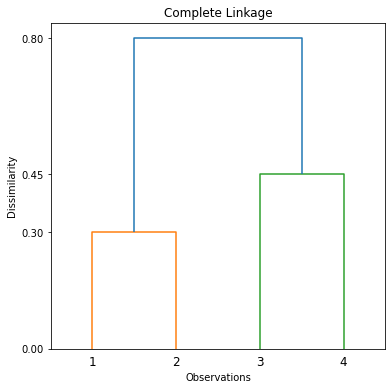

In [39]:
#2a)
array = np.array([
    [0, 0.3, 0.4, 0.7],
    [0.3, 0, 0.5, 0.8],
    [0.4, 0.5, 0, 0.45],
    [0.7, 0.8, 0.45, 0]
])

Z = linkage(squareform(array), method="complete")

plt.figure(figsize=(6,6))
dendrogram(Z, labels=["1","2","3","4"])
plt.ylabel("Dissimilarity")
plt.xlabel("Observations")
plt.yticks([0,0.3,0.45,0.8])
plt.title("Complete Linkage")
plt.show()

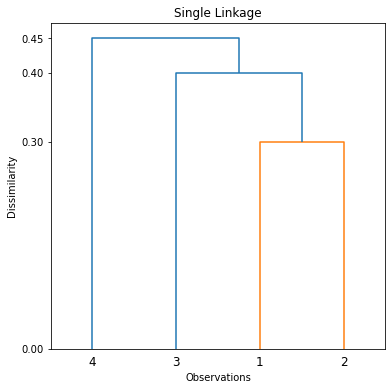

In [38]:
#2b)
Z = linkage(squareform(array), method="single")

plt.figure(figsize=(6,6))
dendrogram(Z, labels=["1","2","3","4"])
plt.ylabel("Dissimilarity")
plt.xlabel("Observations")
plt.yticks([0,0.3,0.4,0.45])
plt.title("Single Linkage")
plt.show()

2c) First fusion occurs b/t observations 1 and 2 at a dissimilarity of 0.3. Second fusion occurs b/t observations 3 and 4 at 0.45. The final fusion occurs at 0.8. So cutting the dendrogram below 0.8 to obtain two clusters gives us:

Cluster 1: Observations 1 and 2

Cluster 2: Observations 3 and 4

2d) Observations 1 and 2 first merge at a dissimilarity of 0.3. Observation 3 joins this cluster at 0.4 and observation 4 at 0.45. So cutting the dendrogram between 0.4 and 0.45 to obtain two clusters gives us:

Cluster 1: Observations 1, 2, and 3

Cluster 2: Observation 4

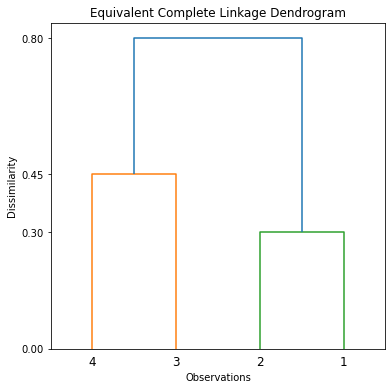

In [41]:
Z = linkage(squareform(array), method="complete")
Z[:, [0, 1]] = Z[:, [1, 0]]

plt.figure(figsize=(6,6))
dendrogram(Z, labels=["1","2","3","4"])
plt.ylabel("Dissimilarity")
plt.xlabel("Observations")
plt.yticks([0,0.3,0.45,0.8])
plt.title("Equivalent Complete Linkage Dendrogram")
plt.show()